In [ ]:
import sys

print(sys.executable)

In [1]:
import pandas as pd

df = pd.read_csv("fish_perch_polynomial.csv")

df.head()

,Species,Weight,Length1,Length2,Length3,Height,Width
0,Perch,5.9,7.5,8.4,8.8,2.1120,1.4080
1,Perch,32.0,12.5,13.7,14.7,3.5280,1.9992
2,Perch,40.0,13.8,15.0,16.0,3.8240,2.4320
3,Perch,51.5,15.0,16.2,17.2,4.5924,2.6316
4,Perch,70.0,15.7,17.4,18.5,4.5880,2.9415


In [2]:
print("Shape:", df.shape)

print("\nColumns:", df.columns.tolist())

df.info()

Shape: (56, 7)

Columns: ['Species', 'Weight', 'Length1', 'Length2', 'Length3', 'Height', 'Width']
<class 'pandas.DataFrame'>
RangeIndex: 56 entries, 0 to 55
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Species  56 non-null     str    
 1   Weight   56 non-null     float64
 2   Length1  56 non-null     float64
 3   Length2  56 non-null     float64
 4   Length3  56 non-null     float64
 5   Height   56 non-null     float64
 6   Width    56 non-null     float64
dtypes: float64(6), str(1)
memory usage: 3.2 KB


In [3]:
df[["Length3", "Weight"]].describe()

,Length3,Weight
count,56.000000,56.000000
mean,29.571429,382.239286
std,9.529509,347.617717
min,8.800000,5.900000
25%,23.325000,120.000000
50%,26.750000,207.500000
75%,39.075000,692.500000
max,46.600000,1100.000000


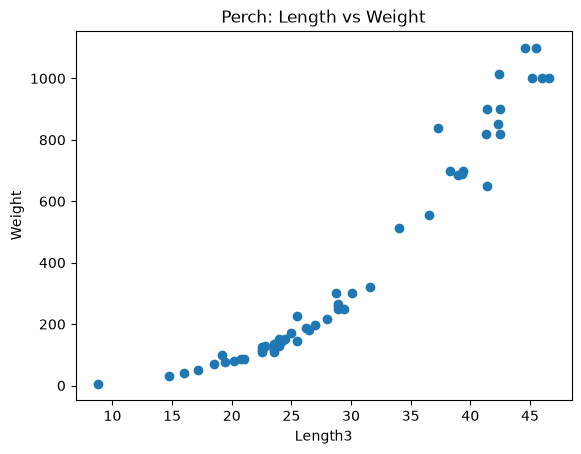

In [4]:
import matplotlib.pyplot as plt

plt.scatter(df["Length3"], df["Weight"])

plt.xlabel("Length3")
plt.ylabel("Weight")
plt.title("Perch: Length vs Weight")

plt.show()

In [5]:
from sklearn.model_selection import train_test_split

X = df[["Length3"]]
y = df["Weight"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Train:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (44, 1) (44,)
Test: (12, 1) (12,)


In [6]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

print("b0 (intercept):", linear_model.intercept_)
print("b1 (slope):", linear_model.coef_[0])

b0 (intercept): -719.8848978736931
b1 (slope): 37.02916107362254


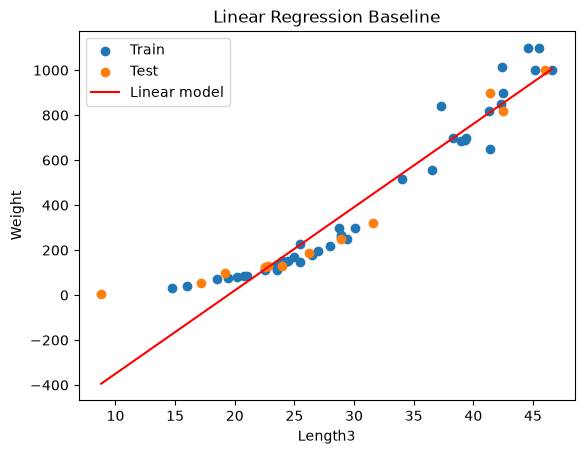

In [7]:
X_line = X.sort_values("Length3")
y_line = linear_model.predict(X_line)

plt.scatter(X_train["Length3"], y_train, label="Train")
plt.scatter(X_test["Length3"], y_test, label="Test")

plt.plot(X_line["Length3"], y_line, color="red", label="Linear model")

plt.xlabel("Length3")
plt.ylabel("Weight")
plt.title("Linear Regression Baseline")
plt.legend()
plt.show()

In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred_linear = linear_model.predict(X_test)

linear_mae = mean_absolute_error(y_test, y_pred_linear)
linear_mse = mean_squared_error(y_test, y_pred_linear)
linear_rmse = linear_mse ** 0.5
linear_r2 = r2_score(y_test, y_pred_linear)

print("Linear Test MAE:", linear_mae)
print("Linear Test MSE:", linear_mse)
print("Linear Test RMSE:", linear_rmse)
print("Linear Test R²:", linear_r2)

Linear Test MAE: 94.12912643574246
Linear Test MSE: 19285.686016251584
Linear Test RMSE: 138.87291318414682
Linear Test R²: 0.834432528775081


In [9]:
from sklearn.preprocessing import PolynomialFeatures

poly2 = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly2 = poly2.fit_transform(X_train)
X_test_poly2 = poly2.transform(X_test)

print("Before:", X_train.shape)
print("After:", X_train_poly2.shape)

print("\nFirst 5 transformed rows:")
print(X_train_poly2[:5])

Before: (44, 1)
After: (44, 2)

First 5 transformed rows:
[[ 29.4  864.36]
 [ 28.7  823.69]
 [ 20.8  432.64]
 [ 23.5  552.25]
 [ 19.4  376.36]]


In [10]:
poly2_model = LinearRegression()

poly2_model.fit(X_train_poly2, y_train)

print("b0 (intercept):", poly2_model.intercept_)
print("b1 (Length3):", poly2_model.coef_[0])
print("b2 (Length3²):", poly2_model.coef_[1])

b0 (intercept): 126.14641236714874
b1 (Length3): -21.188841692479944
b2 (Length3²): 0.9181668579157867


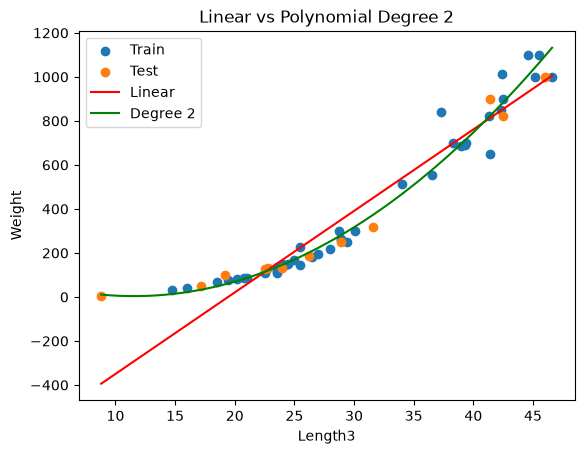

In [11]:
import numpy as np

X_curve = pd.DataFrame({
    "Length3": np.linspace(X["Length3"].min(), X["Length3"].max(), 200)
})

X_curve_poly2 = poly2.transform(X_curve)

plt.scatter(X_train["Length3"], y_train, label="Train")
plt.scatter(X_test["Length3"], y_test, label="Test")

plt.plot(
    X_curve["Length3"],
    linear_model.predict(X_curve),
    color="red",
    label="Linear"
)

plt.plot(
    X_curve["Length3"],
    poly2_model.predict(X_curve_poly2),
    color="green",
    label="Degree 2"
)

plt.xlabel("Length3")
plt.ylabel("Weight")
plt.title("Linear vs Polynomial Degree 2")
plt.legend()
plt.show()

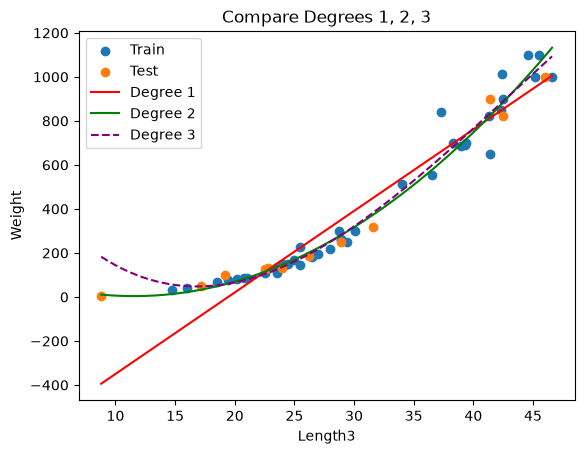

In [12]:
poly3 = PolynomialFeatures(degree=3, include_bias=False)

X_train_poly3 = poly3.fit_transform(X_train)
X_test_poly3 = poly3.transform(X_test)

poly3_model = LinearRegression()
poly3_model.fit(X_train_poly3, y_train)

X_curve_poly3 = poly3.transform(X_curve)

plt.scatter(X_train["Length3"], y_train, label="Train")
plt.scatter(X_test["Length3"], y_test, label="Test")

plt.plot(
    X_curve["Length3"],
    linear_model.predict(X_curve),
    label="Degree 1", color="red"
)

plt.plot(
    X_curve["Length3"],
    poly2_model.predict(X_curve_poly2),
    label="Degree 2", color="green"
)

plt.plot(
    X_curve["Length3"],
    poly3_model.predict(X_curve_poly3),
    label="Degree 3", color="purple", linestyle="--"
)

plt.xlabel("Length3")
plt.ylabel("Weight")
plt.title("Compare Degrees 1, 2, 3")
plt.legend()
plt.show()

In [13]:
results = []

models = [
    ("Degree 1", linear_model, X_train, X_test),
    ("Degree 2", poly2_model, X_train_poly2, X_test_poly2),
    ("Degree 3", poly3_model, X_train_poly3, X_test_poly3)
]

for name, model, train_features, test_features in models:
    train_pred = model.predict(train_features)
    test_pred = model.predict(test_features)

    results.append({
        "Model": name,
        "Train RMSE": mean_squared_error(y_train, train_pred) ** 0.5,
        "Test RMSE": mean_squared_error(y_test, test_pred) ** 0.5,
        "Train R²": r2_score(y_train, train_pred),
        "Test R²": r2_score(y_test, test_pred)
    })

comparison = pd.DataFrame(results)

comparison.round(3)

,Model,Train RMSE,Test RMSE,Train R²,Test R²
0,Degree 1,85.189,138.873,0.939,0.834
1,Degree 2,57.951,46.160,0.972,0.982
2,Degree 3,55.920,65.890,0.974,0.963
